# VEIQ Case C — Market scale analysis

**Constraint:** ≤ 2 GB RAM, ≤ 5 minutes. Measure both.

**Stack:** DuckDB over parquet (no full pandas load).

**Status:** Q1–Q5 complete. One-pager: `WRITEUP.md`. CLI: `python scripts/full_answers.py`.


## 0. Setup

In [2]:
from __future__ import annotations

import time
from pathlib import Path

import duckdb
import psutil

PARQUET = Path("case-c_market.parquet").resolve()
assert PARQUET.exists(), f"Missing data file: {PARQUET}"

REF_YEAR = 2026
MEMORY_LIMIT = "1800MB"
PROCESS = psutil.Process()

CAR_KEY = """
  lower(trim(brand)) || '|' ||
  lower(trim(model)) || '|' ||
  CAST(first_registration_year AS VARCHAR) || '|' ||
  CAST(mileage_km AS VARCHAR) || '|' ||
  COALESCE(CAST(ROUND(power_kw, 0) AS VARCHAR), 'NA') || '|' ||
  seller_ref
"""


def rss_mb() -> float:
    return PROCESS.memory_info().rss / (1024 ** 2)


class RunBudget:
    def __init__(self) -> None:
        self.t0 = time.perf_counter()
        self.peak_rss_mb = rss_mb()

    def tick(self) -> None:
        self.peak_rss_mb = max(self.peak_rss_mb, rss_mb())

    def report(self) -> dict[str, float]:
        self.tick()
        return {
            "elapsed_sec": round(time.perf_counter() - self.t0, 2),
            "peak_rss_mb": round(self.peak_rss_mb, 1),
            "current_rss_mb": round(rss_mb(), 1),
        }


budget = RunBudget()
con = duckdb.connect()
con.execute(f"SET memory_limit='{MEMORY_LIMIT}'")
con.execute("SET threads TO 4")
con.execute(f"CREATE OR REPLACE VIEW listings AS SELECT * FROM '{PARQUET.as_posix()}'")

ANSWERS: dict = {"definitions": {}}
print("start RSS MB:", round(rss_mb(), 1))
budget.tick()

start RSS MB: 88.6


## Q1 — Supply

### Definition
- **Car key** = `lower(brand)|lower(model)|first_registration_year|mileage_km|round(power_kw)|seller_ref`
- **On the market** = rows with `still_active=True`, deduped by car key (point-in-time supply)
- Also report **all-time** distinct cars (any status)

### Why this key
- `listing_id` is unique per ad (1.0M), not per vehicle
- Exclude `asking_price` (moves between posts) and `source` (cross-post target)
- Include `seller_ref` so two dealers with the same popular SKU are not collapsed
- Empirically: most duplicate pairs are **sequential relists** (~17.9k), not concurrent cross-marketplace copies (~210)

In [3]:
q1 = con.execute(
    f"""
    SELECT
      COUNT(*) AS n_listings,
      COUNT(DISTINCT listing_id) AS n_listing_ids,
      COUNT(DISTINCT {CAR_KEY}) AS n_cars_all_time,
      COUNT(DISTINCT CASE WHEN still_active THEN {CAR_KEY} END) AS n_cars_active,
      SUM(CASE WHEN still_active THEN 1 ELSE 0 END) AS n_active_listings
    FROM listings
    """
).df()
display(q1)

q1_pairs = con.execute(
    f"""
    WITH k AS (
      SELECT {CAR_KEY} AS car_key, source, first_seen, last_seen, listing_id
      FROM listings
    ),
    pairs AS (
      SELECT
        CASE WHEN a.first_seen <= b.last_seen AND b.first_seen <= a.last_seen
             THEN 1 ELSE 0 END AS is_overlap,
        CASE WHEN a.source != b.source THEN 1 ELSE 0 END AS is_cross
      FROM k a
      JOIN k b ON a.car_key = b.car_key AND a.listing_id < b.listing_id
    )
    SELECT
      COUNT(*) AS duplicate_pairs,
      SUM(is_overlap) AS overlapping_pairs,
      SUM(1 - is_overlap) AS sequential_pairs,
      SUM(CASE WHEN is_overlap = 1 AND is_cross = 1 THEN 1 ELSE 0 END)
        AS concurrent_cross_source_pairs
    FROM pairs
    """
).df()
display(q1_pairs)

ANSWERS["definitions"]["Q1"] = (
    "car_key=brand|model|year|mileage|round(power_kw)|seller_ref; "
    "on-market = still_active deduped"
)
ANSWERS["Q1_distinct_cars_on_market"] = int(q1.loc[0, "n_cars_active"])
ANSWERS["Q1_all_time_distinct_cars"] = int(q1.loc[0, "n_cars_all_time"])
budget.tick()
print(
    f"HEADLINE Q1: {ANSWERS['Q1_distinct_cars_on_market']:,} distinct cars on market "
    f"(all-time unique cars: {ANSWERS['Q1_all_time_distinct_cars']:,})"
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,n_listings,n_listing_ids,n_cars_all_time,n_cars_active,n_active_listings
0,1000000,1000000,981920,360007,360091.0


,duplicate_pairs,overlapping_pairs,sequential_pairs,concurrent_cross_source_pairs
0,18084,233.0,17851.0,210.0


HEADLINE Q1: 360,007 distinct cars on market (all-time unique cars: 981,920)


## Q2 — Liquidity

### Definition
- **Outcome:** median `date_diff('day', first_seen, last_seen)` among `status_raw = 'sold'` only
- **Drop** rows with `last_seen < first_seen`
- **Always report** `% still_active` (≈36%) so censoring is visible — do **not** average only finished listings and call it time-to-sale
- Prefer **sold** over **removed** (removal ≠ sale)

### Segments
Primary: **seller_type** (clearest gap). Also price band and body type. Fuel is nearly flat.

In [4]:
q2_seller = con.execute(
    """
    SELECT seller_type,
      COUNT(*) AS n,
      SUM(CASE WHEN status_raw = 'sold' THEN 1 ELSE 0 END) AS n_sold,
      ROUND(100.0 * AVG(CASE WHEN still_active THEN 1.0 ELSE 0.0 END), 1)
        AS pct_still_active,
      ROUND(MEDIAN(CASE WHEN status_raw = 'sold'
                        THEN date_diff('day', first_seen, last_seen) END), 1)
        AS median_days_to_sold
    FROM listings
    WHERE last_seen >= first_seen AND asking_price_eur >= 500
    GROUP BY 1
    ORDER BY median_days_to_sold
    """
).df()
display(q2_seller)

q2_price = con.execute(
    """
    SELECT
      CASE
        WHEN asking_price_eur < 10000 THEN '<10k'
        WHEN asking_price_eur < 20000 THEN '10-20k'
        WHEN asking_price_eur < 35000 THEN '20-35k'
        ELSE '35k+'
      END AS price_band,
      COUNT(*) AS n,
      ROUND(100.0 * AVG(CASE WHEN still_active THEN 1.0 ELSE 0.0 END), 1)
        AS pct_still_active,
      ROUND(MEDIAN(CASE WHEN status_raw = 'sold'
                        THEN date_diff('day', first_seen, last_seen) END), 1)
        AS median_days_to_sold
    FROM listings
    WHERE last_seen >= first_seen AND asking_price_eur >= 500
    GROUP BY 1
    ORDER BY median_days_to_sold
    """
).df()
display(q2_price)

q2_body = con.execute(
    """
    SELECT body_type,
      COUNT(*) AS n,
      ROUND(100.0 * AVG(CASE WHEN still_active THEN 1.0 ELSE 0.0 END), 1)
        AS pct_still_active,
      ROUND(MEDIAN(CASE WHEN status_raw = 'sold'
                        THEN date_diff('day', first_seen, last_seen) END), 1)
        AS median_days_to_sold
    FROM listings
    WHERE last_seen >= first_seen AND asking_price_eur >= 500
    GROUP BY 1
    HAVING COUNT(*) >= 5000
    ORDER BY median_days_to_sold
    """
).df()
display(q2_body)

q2_fuel = con.execute(
    """
    SELECT fuel_type,
      COUNT(*) AS n,
      ROUND(100.0 * AVG(CASE WHEN still_active THEN 1.0 ELSE 0.0 END), 1)
        AS pct_still_active,
      ROUND(MEDIAN(CASE WHEN status_raw = 'sold'
                        THEN date_diff('day', first_seen, last_seen) END), 1)
        AS median_days_to_sold
    FROM listings
    WHERE last_seen >= first_seen AND asking_price_eur >= 500
    GROUP BY 1
    ORDER BY median_days_to_sold
    """
).df()
display(q2_fuel)

ANSWERS["definitions"]["Q2"] = (
    "median days among status_raw=sold; drop inverted dates; report pct still_active"
)
ANSWERS["Q2_fastest"] = "private sellers: 26d median to sold vs dealers 30d"
ANSWERS["Q2_also"] = "cheaper bands faster (<10k: 28d → 35k+: 33d); sedan slowest body (31d)"
budget.tick()
print("HEADLINE Q2:", ANSWERS["Q2_fastest"])

,seller_type,n,n_sold,pct_still_active,median_days_to_sold
0,private,208165,16329.0,32.6,26.0
1,dealer,779717,57397.0,36.8,30.0


,price_band,n,pct_still_active,median_days_to_sold
0,<10k,456060,34.9,28.0
1,10-20k,361509,36.2,30.0
2,20-35k,148104,37.6,31.0
3,35k+,22209,39.6,33.0


,body_type,n,pct_still_active,median_days_to_sold
0,SUV,215682,36.2,29.0
1,HATCHBACK,686941,35.7,29.0
2,WAGON,39997,36.4,30.0
3,SEDAN,45262,36.4,31.0


,fuel_type,n,pct_still_active,median_days_to_sold
0,diesel,142402,36.2,29.0
1,hybrid,165755,36.0,29.0
2,electric,91921,35.7,29.0
3,petrol,587804,35.8,29.0


HEADLINE Q2: private sellers: 26d median to sold vs dealers 30d


## Q3 — Price by age (per fuel), controlled for mileage

### Definition
- **Age** = `2026 - first_registration_year`
- **Filters:** price €500–150k; year 2005–2026; age 0–15
- **Controlled for mileage** means: estimate `regr_slope(asking_price_eur, age)` **inside** mileage bins
  (`0–50k`, `50–100k`, `100–150k`, `150k+`), not a raw age–price correlation (mileage confounds age)
- **Headline band:** `50–100k` km (large mid-life stock); also show median price vs age curve in that band

,fuel_type,km_bin,n,eur_per_year_of_age,median_price
0,diesel,0-50k,31584,-3565.5,24698.0
1,diesel,100-150k,28115,-1511.1,10500.0
2,diesel,150k+,35371,-1051.4,5600.0
3,diesel,50-100k,42314,-2270.9,15750.0
4,electric,0-50k,30830,-3590.2,18750.0
5,electric,100-150k,15275,-964.9,6425.0
6,electric,150k+,11968,-688.8,3700.0
7,electric,50-100k,30452,-1575.9,10300.0
8,hybrid,0-50k,55916,-3183.6,21650.0
9,hybrid,100-150k,27060,-1202.8,8050.0


,fuel_type,eur_per_year_of_age,n
3,diesel,-2270.9,42314
11,hybrid,-1832.1,55161
7,electric,-1575.9,30452
15,petrol,-1458.9,195586


,fuel_type,age,n,median_price
0,diesel,2,1102,26250.0
1,diesel,3,5886,22404.0
2,diesel,4,9640,19150.0
3,diesel,5,9454,16342.0
4,diesel,6,6843,14100.0
5,diesel,7,4263,12100.0
6,diesel,8,2388,10474.0
7,diesel,9,1345,8850.0
8,diesel,10,701,7762.0
9,diesel,11,333,7068.0


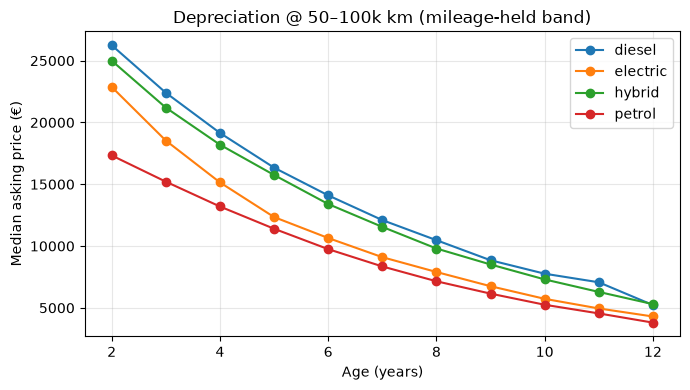

HEADLINE Q3 (€/year of age @ 50–100k km): {'diesel': -2270.9, 'hybrid': -1832.1, 'electric': -1575.9, 'petrol': -1458.9}


In [5]:
q3_within = con.execute(
    f"""
    WITH b AS (
      SELECT fuel_type,
        CASE
          WHEN mileage_km < 50000 THEN '0-50k'
          WHEN mileage_km < 100000 THEN '50-100k'
          WHEN mileage_km < 150000 THEN '100-150k'
          ELSE '150k+'
        END AS km_bin,
        {REF_YEAR} - first_registration_year AS age,
        asking_price_eur
      FROM listings
      WHERE asking_price_eur BETWEEN 500 AND 150000
        AND first_registration_year BETWEEN 2005 AND {REF_YEAR}
        AND ({REF_YEAR} - first_registration_year) BETWEEN 0 AND 15
    )
    SELECT fuel_type, km_bin, COUNT(*) AS n,
      ROUND(regr_slope(asking_price_eur, age), 1) AS eur_per_year_of_age,
      ROUND(MEDIAN(asking_price_eur), 0) AS median_price
    FROM b
    GROUP BY 1, 2
    HAVING COUNT(*) >= 500
    ORDER BY fuel_type, km_bin
    """
).df()
display(q3_within)

q3_headline = q3_within[q3_within["km_bin"] == "50-100k"][
    ["fuel_type", "eur_per_year_of_age", "n"]
].sort_values("eur_per_year_of_age")
display(q3_headline)

q3_curve = con.execute(
    f"""
    WITH b AS (
      SELECT fuel_type,
        {REF_YEAR} - first_registration_year AS age,
        asking_price_eur
      FROM listings
      WHERE asking_price_eur BETWEEN 500 AND 150000
        AND first_registration_year BETWEEN 2005 AND {REF_YEAR}
        AND mileage_km BETWEEN 50000 AND 99999
    )
    SELECT fuel_type, age, COUNT(*) AS n,
      ROUND(MEDIAN(asking_price_eur), 0) AS median_price
    FROM b
    WHERE age BETWEEN 2 AND 12
    GROUP BY 1, 2
    HAVING COUNT(*) >= 50
    ORDER BY fuel_type, age
    """
).df()
display(q3_curve.head(20))

try:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7, 4))
    for fuel, g in q3_curve.groupby("fuel_type"):
        ax.plot(g["age"], g["median_price"], marker="o", label=fuel)
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Median asking price (€)")
    ax.set_title("Depreciation @ 50–100k km (mileage-held band)")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Plot skipped:", exc)

ANSWERS["definitions"]["Q3"] = (
    "controlled-for-mileage = age slope inside mileage bins; headline = 50-100k km"
)
ANSWERS["Q3_eur_per_year_50_100k"] = {
    r.fuel_type: float(r.eur_per_year_of_age) for r in q3_headline.itertuples()
}
budget.tick()
print("HEADLINE Q3 (€/year of age @ 50–100k km):", ANSWERS["Q3_eur_per_year_50_100k"])

## Q4 — Private vs dealer on comparable cars

### Definition
- **Comparable cell** = `brand|model|reg_year|fuel|body|mileage_bin`
- Cell kept if **≥3 private** and **≥3 dealer** listings (after price €500–150k, year 2005–2026)
- **Gap** = median over cells of `(median_private − median_dealer)` (EUR and % of dealer median)
- Unmatched overall medians are **not** used as the answer (mix differs by seller type)

In [6]:
q4 = con.execute(
    """
    WITH base AS (
      SELECT
        lower(trim(brand)) AS brand,
        lower(trim(model)) AS model,
        first_registration_year AS reg_year,
        fuel_type,
        body_type,
        seller_type,
        asking_price_eur,
        CASE
          WHEN mileage_km < 50000 THEN '0-50k'
          WHEN mileage_km < 100000 THEN '50-100k'
          WHEN mileage_km < 150000 THEN '100-150k'
          ELSE '150k+'
        END AS mileage_bin
      FROM listings
      WHERE asking_price_eur BETWEEN 500 AND 150000
        AND first_registration_year BETWEEN 2005 AND 2026
    ),
    cells AS (
      SELECT
        brand, model, reg_year, fuel_type, body_type, mileage_bin,
        MEDIAN(CASE WHEN seller_type = 'private' THEN asking_price_eur END) AS med_private,
        MEDIAN(CASE WHEN seller_type = 'dealer' THEN asking_price_eur END) AS med_dealer
      FROM base
      GROUP BY 1, 2, 3, 4, 5, 6
      HAVING SUM(CASE WHEN seller_type = 'private' THEN 1 ELSE 0 END) >= 3
         AND SUM(CASE WHEN seller_type = 'dealer' THEN 1 ELSE 0 END) >= 3
    )
    SELECT
      COUNT(*) AS n_comparable_cells,
      ROUND(MEDIAN(med_private - med_dealer), 0) AS median_gap_eur,
      ROUND(AVG(med_private - med_dealer), 0) AS mean_gap_eur,
      ROUND(100.0 * MEDIAN((med_private - med_dealer) / NULLIF(med_dealer, 0)), 2)
        AS median_gap_pct,
      ROUND(100.0 * AVG(CASE WHEN med_private < med_dealer THEN 1.0 ELSE 0.0 END), 1)
        AS pct_cells_private_cheaper
    FROM cells
    """
).df()
display(q4)

q4_fuel = con.execute(
    """
    WITH base AS (
      SELECT
        lower(trim(brand)) AS brand,
        lower(trim(model)) AS model,
        first_registration_year AS reg_year,
        fuel_type, body_type, seller_type, asking_price_eur,
        CASE
          WHEN mileage_km < 50000 THEN '0-50k'
          WHEN mileage_km < 100000 THEN '50-100k'
          WHEN mileage_km < 150000 THEN '100-150k'
          ELSE '150k+'
        END AS mileage_bin
      FROM listings
      WHERE asking_price_eur BETWEEN 500 AND 150000
        AND first_registration_year BETWEEN 2005 AND 2026
    ),
    cells AS (
      SELECT fuel_type,
        MEDIAN(CASE WHEN seller_type = 'private' THEN asking_price_eur END) AS med_private,
        MEDIAN(CASE WHEN seller_type = 'dealer' THEN asking_price_eur END) AS med_dealer
      FROM base
      GROUP BY brand, model, reg_year, fuel_type, body_type, mileage_bin
      HAVING SUM(CASE WHEN seller_type = 'private' THEN 1 ELSE 0 END) >= 3
         AND SUM(CASE WHEN seller_type = 'dealer' THEN 1 ELSE 0 END) >= 3
    )
    SELECT fuel_type, COUNT(*) AS n_cells,
      ROUND(MEDIAN(med_private - med_dealer), 0) AS median_gap_eur,
      ROUND(100.0 * MEDIAN((med_private - med_dealer) / NULLIF(med_dealer, 0)), 2)
        AS median_gap_pct
    FROM cells
    GROUP BY 1
    ORDER BY 1
    """
).df()
display(q4_fuel)

# Sensitivity to cell size threshold
q4_sens = con.execute(
    """
    WITH base AS (
      SELECT lower(trim(brand)) brand, lower(trim(model)) model,
             first_registration_year AS reg_year, fuel_type, body_type, seller_type,
             asking_price_eur,
             CASE WHEN mileage_km < 50000 THEN '0-50k'
                  WHEN mileage_km < 100000 THEN '50-100k'
                  WHEN mileage_km < 150000 THEN '100-150k'
                  ELSE '150k+' END mileage_bin
      FROM listings
      WHERE asking_price_eur BETWEEN 500 AND 150000
        AND first_registration_year BETWEEN 2005 AND 2026
    )
    SELECT min_n,
      (SELECT COUNT(*) FROM (
         SELECT 1 FROM base
         GROUP BY brand, model, reg_year, fuel_type, body_type, mileage_bin
         HAVING SUM(CASE WHEN seller_type='private' THEN 1 ELSE 0 END) >= min_n
            AND SUM(CASE WHEN seller_type='dealer' THEN 1 ELSE 0 END) >= min_n
       )) AS n_cells,
      (SELECT ROUND(MEDIAN(med_p - med_d), 0) FROM (
         SELECT MEDIAN(CASE WHEN seller_type='private' THEN asking_price_eur END) med_p,
                MEDIAN(CASE WHEN seller_type='dealer' THEN asking_price_eur END) med_d
         FROM base
         GROUP BY brand, model, reg_year, fuel_type, body_type, mileage_bin
         HAVING SUM(CASE WHEN seller_type='private' THEN 1 ELSE 0 END) >= min_n
            AND SUM(CASE WHEN seller_type='dealer' THEN 1 ELSE 0 END) >= min_n
       )) AS median_gap_eur
    FROM (SELECT * FROM (VALUES (1), (3), (5), (10)) v(min_n))
    """
).df()
display(q4_sens)

ANSWERS["definitions"]["Q4"] = (
    "comparable=brand|model|year|fuel|body|mileage_bin; ≥3 each side; "
    "gap=median(med_private-med_dealer)"
)
ANSWERS["Q4_median_gap_eur"] = float(q4.loc[0, "median_gap_eur"])
ANSWERS["Q4_median_gap_pct"] = float(q4.loc[0, "median_gap_pct"])
ANSWERS["Q4_n_cells"] = int(q4.loc[0, "n_comparable_cells"])
budget.tick()
print(
    f"HEADLINE Q4: private undercuts dealer by "
    f"€{ANSWERS['Q4_median_gap_eur']:.0f} ({ANSWERS['Q4_median_gap_pct']:.1f}%) "
    f"on {ANSWERS['Q4_n_cells']:,} comparable cells"
)

,n_comparable_cells,median_gap_eur,mean_gap_eur,median_gap_pct,pct_cells_private_cheaper
0,5247,-505.0,-717.0,-7.04,89.8


,fuel_type,n_cells,median_gap_eur,median_gap_pct
0,diesel,1298,-600.0,-6.85
1,electric,623,-400.0,-7.02
2,hybrid,1389,-550.0,-7.07
3,petrol,1937,-452.0,-7.12


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_n,n_cells,median_gap_eur
0,1,6489,-463.0
1,3,5247,-505.0
2,5,4573,-542.0
3,10,3529,-580.0


HEADLINE Q4: private undercuts dealer by €-505 (-7.0%) on 5,247 comparable cells


## Q5 — Something is wrong (≥5 issues documented)

For each: **evidence → breaks which of Q1–Q4 → handling**.
Narrative write-up: [`WRITEUP.md`](WRITEUP.md).


In [7]:
patho = con.execute(
    """
    SELECT
      SUM(CASE WHEN asking_price_eur <= 1 THEN 1 ELSE 0 END) AS price_le_1,
      SUM(CASE WHEN asking_price_eur < 500 THEN 1 ELSE 0 END) AS price_lt_500,
      SUM(CASE WHEN first_registration_year = 1900 THEN 1 ELSE 0 END) AS year_1900,
      SUM(CASE WHEN first_registration_year > 2026 THEN 1 ELSE 0 END) AS year_gt_2026,
      SUM(CASE WHEN last_seen < first_seen THEN 1 ELSE 0 END) AS inverted_dates,
      SUM(CASE WHEN power_kw IS NULL THEN 1 ELSE 0 END) AS power_kw_null
    FROM listings
    """
).df()
display(patho)

relist = con.execute(
    f"""
    WITH k AS (
      SELECT {CAR_KEY} AS car_key, listing_id, source, status_raw,
             first_seen, last_seen,
             date_diff('day', first_seen, last_seen) AS spell_days,
             ROW_NUMBER() OVER (
               PARTITION BY {CAR_KEY} ORDER BY first_seen, listing_id
             ) AS rn
      FROM listings
      WHERE last_seen >= first_seen
    ),
    seq AS (
      SELECT a.status_raw AS status_1, a.spell_days AS prior_spell_days,
             a.source AS s1, b.source AS s2
      FROM k a
      JOIN k b ON a.car_key = b.car_key AND b.rn = a.rn + 1
    )
    SELECT COUNT(*) AS sequential_relist_pairs,
      SUM(CASE WHEN status_1 = 'sold' THEN 1 ELSE 0 END) AS prior_marked_sold,
      SUM(CASE WHEN prior_spell_days <= 7 THEN 1 ELSE 0 END) AS prior_spell_le_7d,
      SUM(CASE WHEN s1 = s2 THEN 1 ELSE 0 END) AS same_source_relist
    FROM seq
    """
).df()
display(relist)

# Evidence samples
display(con.execute(
    """
    SELECT listing_id, brand, model, asking_price_eur, first_registration_year,
           status_raw, source
    FROM listings WHERE asking_price_eur <= 1 LIMIT 5
    """
).df())
display(con.execute(
    """
    SELECT listing_id, first_registration_year, asking_price_eur, mileage_km
    FROM listings
    WHERE first_registration_year IN (1900, 2027, 2028)
    LIMIT 5
    """
).df())
display(con.execute(
    """
    SELECT listing_id, first_seen, last_seen,
           date_diff('day', first_seen, last_seen) AS days, still_active
    FROM listings WHERE last_seen < first_seen LIMIT 5
    """
).df())

ANSWERS["Q5_issues"] = [
    {
        "issue": "€1 / placeholder prices",
        "n": int(patho.loc[0, "price_le_1"]),
        "breaks": ["Q3", "Q4"],
        "handle": "Exclude asking_price_eur < 500; prefer medians",
    },
    {
        "issue": "Impossible years (1900, 2027, 2028)",
        "n_1900": int(patho.loc[0, "year_1900"]),
        "n_future": int(patho.loc[0, "year_gt_2026"]),
        "breaks": ["Q3", "Q4"],
        "handle": "Filter year to 2005–2026",
    },
    {
        "issue": "Inverted dates last_seen < first_seen",
        "n": int(patho.loc[0, "inverted_dates"]),
        "breaks": ["Q2"],
        "handle": "Drop from duration stats",
    },
    {
        "issue": "Relists after sold / short spells",
        "pairs": int(relist.loc[0, "sequential_relist_pairs"]),
        "prior_sold": int(relist.loc[0, "prior_marked_sold"]),
        "breaks": ["Q2", "Q1"],
        "handle": "Q1 car-key dedupe; flag Q2 sold reliability",
    },
    {
        "issue": "Null power_kw (~28%)",
        "n": int(patho.loc[0, "power_kw_null"]),
        "breaks": ["Q1"],
        "handle": "Key maps null→NA; supply may be slightly understated",
    },
]
budget.tick()
ANSWERS["Q5_issues"]


,price_le_1,price_lt_500,year_1900,year_gt_2026,inverted_dates,power_kw_null
0,3981.0,7860.0,968.0,1943.0,4284.0,279355.0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,sequential_relist_pairs,prior_marked_sold,prior_spell_le_7d,same_source_relist
0,18078,2144.0,2116.0,17862.0


,listing_id,brand,model,asking_price_eur,first_registration_year,status_raw,source
0,00000009a0b1,mercedes-benz,A-Klasse,1,2021,sold,dealerdirect
1,000000018684,mercedes-benz,A-Klasse,1,2017,removed,autogids
2,0000000eca85,fiat,500,1,2012,removed,carbourse
3,0000000010d6,opel,Corsa,1,2024,active,vierwielers
4,000000086754,renault,Clio,1,2023,removed,wielenmarkt


,listing_id,first_registration_year,asking_price_eur,mileage_km
0,0000000c8628,2028,7650,125439
1,00000005d9d3,2028,7149,150609
2,0000000b1fd9,2028,15700,31575
3,00000005020c,2027,10250,36997
4,00000000b1bb,2028,4572,93958


,listing_id,first_seen,last_seen,days,still_active
0,0000000965cf,2026-07-02,2026-07-01,-1,True
1,00000006e8d3,2026-06-28,2026-06-27,-1,False
2,0000000257b9,2026-07-03,2026-07-01,-2,True
3,00000001bf35,2026-07-02,2026-07-01,-1,True
4,000000026d0f,2026-02-16,2026-02-14,-2,False


[{'issue': '€1 / placeholder prices',
  'n': 3981,
  'breaks': ['Q3', 'Q4'],
  'handle': 'Exclude asking_price_eur < 500; prefer medians'},
 {'issue': 'Impossible years (1900, 2027, 2028)',
  'n_1900': 968,
  'n_future': 1943,
  'breaks': ['Q3', 'Q4'],
  'handle': 'Filter year to 2005–2026'},
 {'issue': 'Inverted dates last_seen < first_seen',
  'n': 4284,
  'breaks': ['Q2'],
  'handle': 'Drop from duration stats'},
 {'issue': 'Relists after sold / short spells',
  'pairs': 18078,
  'prior_sold': 2144,
  'breaks': ['Q2', 'Q1'],
  'handle': 'Q1 car-key dedupe; flag Q2 sold reliability'},
 {'issue': 'Null power_kw (~28%)',
  'n': 279355,
  'breaks': ['Q1'],
  'handle': 'Key maps null→NA; supply may be slightly understated'}]

## Final summary — copy into one-pager (`WRITEUP.md`)


In [8]:
final = budget.report()
ANSWERS["runtime_sec"] = final["elapsed_sec"]
ANSWERS["peak_rss_mb"] = final["peak_rss_mb"]

print("=== FULL ANSWERS Q1–Q5 ===")
for k, v in ANSWERS.items():
    print(f"{k}: {v}")
print(
    f"\nBudget: {final['elapsed_sec']}s / 300s, "
    f"peak RSS {final['peak_rss_mb']} MB / 2048 MB"
)
print("\nOne-pager: WRITEUP.md")
print("Machine JSON: outputs/full_answers.json (via scripts/full_answers.py)")


=== FULL ANSWERS Q1–Q5 ===
definitions: {'Q1': 'car_key=brand|model|year|mileage|round(power_kw)|seller_ref; on-market = still_active deduped', 'Q2': 'median days among status_raw=sold; drop inverted dates; report pct still_active', 'Q3': 'controlled-for-mileage = age slope inside mileage bins; headline = 50-100k km', 'Q4': 'comparable=brand|model|year|fuel|body|mileage_bin; ≥3 each side; gap=median(med_private-med_dealer)'}
Q1_distinct_cars_on_market: 360007
Q1_all_time_distinct_cars: 981920
Q2_fastest: private sellers: 26d median to sold vs dealers 30d
Q2_also: cheaper bands faster (<10k: 28d → 35k+: 33d); sedan slowest body (31d)
Q3_eur_per_year_50_100k: {'diesel': -2270.9, 'hybrid': -1832.1, 'electric': -1575.9, 'petrol': -1458.9}
Q4_median_gap_eur: -505.0
Q4_median_gap_pct: -7.04
Q4_n_cells: 5247
Q5_issues: [{'issue': '€1 / placeholder prices', 'n': 3981, 'breaks': ['Q3', 'Q4'], 'handle': 'Exclude asking_price_eur < 500; prefer medians'}, {'issue': 'Impossible years (1900, 2027, 2